# CompuOpti: multi-objective staff scheduling with OR-Tools CP-SAT

Decision Modelling project (CentraleSupélec). Everything is in this notebook: data, an independent
checker, the CP-SAT model, two exact Pareto methods, plots in objective and decision space, and an
instance generator.

**Run:** `uv run jupyter lab CompuOpti_staffing.ipynb`, then *Run all*. With the default budgets the
notebook takes about 15 minutes. Raise `BUDGET` to get more medium/large points proven.

In [1]:
import contextlib
import itertools
import json
import random
import time
from collections import defaultdict
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import pandas as pd
from ipywidgets import interact
from ortools.sat.python import cp_model

TL, BUDGET, WORKERS = 10, 120, 8  # seconds per solve, seconds per Pareto front, CPU threads
OBJS = ["profit", "duration", "projects_per_staff", "late_jobs", "team_size", "imbalance"]
BRIEF = OBJS[:4]  # the brief's four objectives; the last two are our extras
BLUE, LIGHT, ORANGE, GREY = "#2a78d6", "#9ec5f4", "#ec835a", "#e1e0d9"

## 1. Data, read as a real staffing problem

* Each employee-day goes to one (project, qualification) pair, or stays idle.
* **A rejected project gets no work at all.** Nobody half-staffs a project that won't be delivered,
  so coverage is an equality: a project is either fully staffed or untouched.
* **Duration is the calendar span** from a project's first to last working day, including holiday
  gaps, because that is the wait the client sees.
* **Only delivered projects can be late.** A dropped project counts as declined, not late.
* All three instances need more person-days than the staff have (demand/capacity > 1), so the real
  decision is *which projects to accept*.

In [2]:
def prepare(d, name="generated"):
    """Index staff/jobs by name and list the legal (staff, job, qual, day) slots."""
    d["name"], d["days"] = name, range(1, d["horizon"] + 1)
    d["S"] = {s["name"]: s for s in d["staff"]}
    d["J"] = {j["name"]: j for j in d["jobs"]}
    for j in d["jobs"]:
        j["req"] = j["working_days_per_qualification"]
    d["slots"] = [
        (s["name"], j["name"], q, t)
        for s in d["staff"]
        for j in d["jobs"]
        for q in j["req"]
        if q in s["qualifications"]
        for t in d["days"]
        if t not in s["vacations"]
    ]
    return d

In [3]:
def stats(I):
    cap = sum(I["horizon"] - len(s["vacations"]) for s in I["staff"])
    demand = sum(sum(j["req"].values()) for j in I["jobs"])
    return {
        "days": I["horizon"],
        "staff": len(I["staff"]),
        "jobs": len(I["jobs"]),
        "x variables": len(I["slots"]),
        "demand / capacity": round(demand / cap, 2),
    }


INST = {
    n: prepare(json.loads(Path(f"Datasets/{n}_instance.json").read_text()), n)
    for n in ["toy", "medium", "large"]
}
pd.DataFrame({n: stats(I) for n, I in INST.items()})

,toy,medium,large
days,5.00,22.00,36.00
staff,3.00,5.00,6.00
jobs,5.00,15.00,25.00
x variables,90.00,1298.00,3939.00
demand / capacity,1.08,1.32,1.41


## 2. Independent checker

A schedule is a dict `{(employee, day): (job, qualification)}`, so "one task per day" holds by
construction. Every number in this notebook comes from `evaluate`, never from the solver's own
variables. That way a modelling mistake can't hide.

In [4]:
def utilisation(I, sched):
    """% of available days worked, for staff who could work on at least one job."""
    load = defaultdict(int)
    for i, _ in sched:
        load[i] += 1
    needed = {q for j in I["jobs"] for q in j["req"]}
    return {
        s["name"]: 100 * load[s["name"]] // (I["horizon"] - len(s["vacations"]))
        for s in I["staff"]
        if needed & set(s["qualifications"]) and len(s["vacations"]) < I["horizon"]
    }

In [5]:
def evaluate(I, sched):
    """Check every hard rule, then compute the six objectives."""
    work = defaultdict(lambda: defaultdict(int))
    days, team, jobs_of = defaultdict(set), defaultdict(set), defaultdict(set)
    for (i, t), (j, q) in sched.items():
        s = I["S"][i]
        assert q in s["qualifications"] and q in I["J"][j]["req"], "skill rule"
        assert t in I["days"] and t not in s["vacations"], "holiday rule"
        work[j][q] += 1
        days[j].add(t)
        team[j].add(i)
        jobs_of[i].add(j)
    assert all(work[j] == I["J"][j]["req"] for j in work), "a job is partly or over-staffed"
    late = {j: max(0, max(days[j]) - I["J"][j]["due_date"]) for j in work}
    util = utilisation(I, sched).values()
    return {
        "profit": sum(I["J"][j]["gain"] - I["J"][j]["daily_penalty"] * late[j] for j in work),
        "duration": max((max(d) - min(d) + 1 for d in days.values()), default=0),
        "projects_per_staff": max(map(len, jobs_of.values()), default=0),
        "late_jobs": sum(v > 0 for v in late.values()),
        "team_size": max(map(len, team.values()), default=0),
        "imbalance": max(util, default=0) - min(util, default=0),
    }

In [6]:
evaluate(INST["toy"], {})  # doing nothing: feasible, every objective 0

{'profit': 0,
 'duration': 0,
 'projects_per_staff': 0,
 'late_jobs': 0,
 'team_size': 0,
 'imbalance': 0}

## 3. The CP-SAT model

| symbol | meaning |
|---|---|
| $x_{i,j,k,t}\in\{0,1\}$ | employee $i$ works on qualification $k$ of job $j$ on day $t$ (created only if $i$ has $k$, $j$ needs $k$, and $t$ is not a holiday) |
| $y_j\in\{0,1\}$ | job $j$ is delivered |
| $a_{j,t}, b_{j,t}, w_{j,t}$ | job $j$ has started by day $t$ / is still open on day $t$ / day $t$ is inside its window |

**Constraints:** $\sum_{j,k}x_{i,j,k,t}\le 1$ (one task per day), and $\sum_{i,t}x_{i,j,k,t}=n_{j,k}\,y_j$
(all or nothing, at most once). Work happens only inside the window: $x\le w$. Then
$\text{span}_j=\sum_t w_{j,t}$ and $\text{late days}_j=\sum_{t>d_j}b_{j,t}$.

| | objective | sense | why it matters |
|---|---|---|---|
| f1 | profit $=\sum g_j y_j-\sum c_j\,\text{late days}_j$ | max | the brief |
| f2 | longest project span | min | the brief: deliver fast |
| f3 | most projects any one employee works on | min | the brief: less context switching |
| f4 | number of late projects | min | the brief: reputation |
| E1 | largest team on a project | min | extra: coordination cost (meetings, hand-overs) |
| E2 | utilisation gap max − min, as % of available days | min | extra: fairness, as % so holidays don't count as idleness |

In [7]:
def group(d, key):
    out = defaultdict(list)
    for k, v in d.items():
        out[key(k)].append(v)
    return out

In [8]:
def add_core(M, I):
    m = M.m
    M.x = {s: m.new_bool_var("") for s in I["slots"]}  # skill + holiday rules by construction
    M.y = {j: m.new_bool_var("") for j in I["J"]}
    for xs in group(M.x, lambda s: (s[0], s[3])).values():
        m.add_at_most_one(xs)  # one task per employee per day
    cover = group(M.x, lambda s: (s[1], s[2]))
    for j, job in I["J"].items():
        for q, n in job["req"].items():
            m.add(sum(cover[j, q]) == n * M.y[j])  # all or nothing

In [9]:
def add_windows(M, I):
    m, h = M.m, I["horizon"]
    M.a, M.b, M.w = ({j: [m.new_bool_var("") for _ in I["days"]] for j in I["J"]} for _ in "abw")
    for j in I["J"]:
        a, b, w = M.a[j], M.b[j], M.w[j]
        for t in range(h - 1):
            m.add_implication(a[t], a[t + 1])  # once started, stays started
            m.add_implication(b[t + 1], b[t])  # once closed, stays closed
        for t in range(h):
            m.add_bool_and([a[t], b[t]]).only_enforce_if(w[t])  # w = a AND b
            m.add_bool_or([w[t], a[t].Not(), b[t].Not()])
            m.add_implication(w[t], M.y[j])
    for (_, j, t), xs in group(M.x, lambda s: s[:2] + s[3:]).items():
        m.add(sum(xs) <= M.w[j][t - 1])  # work only inside the window
    M.late_days = {
        j: sum(M.b[j][job["due_date"] :]) for j, job in I["J"].items() if job["due_date"] < h
    }

In [10]:
def add_cuts(M, I):
    """Valid inequalities: they only speed the solver up."""
    holders = {q: [s for s in I["staff"] if q in s["qualifications"]] for q in I["qualifications"]}
    for q, hs in holders.items():
        cap = sum(I["horizon"] - len(s["vacations"]) for s in hs)
        M.m.add(sum(j["req"][q] * M.y[j["name"]] for j in I["jobs"] if q in j["req"]) <= cap)
    for j, job in I["J"].items():
        span = max(-(-n // max(1, len(holders[q]))) for q, n in job["req"].items())
        M.m.add(sum(M.w[j]) >= span * M.y[j])

Each objective gets one integer variable $v$, linked in one direction only ($v\ge$ true value
for a minimised objective). Optimising, bounding or excluding $v$ is still exact, because the true
values are always a feasible choice of $v$. Reported values come from `evaluate`.

In [11]:
def new_objective(M, name, lo, hi):
    M.v[name], M.dom[name] = M.m.new_int_var(lo, hi, name), (lo, hi)
    return M.v[name]


def f_profit(M, I):
    J, h = I["J"], I["horizon"]
    worst = sum(J[j]["daily_penalty"] * (h - J[j]["due_date"]) for j in M.late_days)
    v = new_objective(M, "profit", -worst, sum(j["gain"] for j in I["jobs"]))
    gains = sum(J[j]["gain"] * M.y[j] for j in J)
    M.m.add(v == gains - sum(J[j]["daily_penalty"] * ld for j, ld in M.late_days.items()))

In [12]:
def f_duration(M, I):
    v = new_objective(M, "duration", 0, I["horizon"])
    for w in M.w.values():
        M.m.add(v >= sum(w))


def f_late_jobs(M, I):
    late = [M.b[j][I["J"][j]["due_date"]] for j in M.late_days]  # still open the day after d_j
    M.m.add(new_objective(M, "late_jobs", 0, len(late)) == sum(late))

In [13]:
def works_on(M):
    """u[i, j] = 1 if employee i does any work on job j."""
    if not hasattr(M, "u"):
        M.u = {k: M.m.new_bool_var("") for k in group(M.x, lambda s: s[:2])}
        for s, x in M.x.items():
            M.m.add_implication(x, M.u[s[:2]])
    return M.u


def f_projects_per_staff(M, I):
    v = new_objective(M, "projects_per_staff", 0, len(I["jobs"]))
    for us in group(works_on(M), lambda k: k[0]).values():
        M.m.add(v >= sum(us))


def f_team_size(M, I):
    v = new_objective(M, "team_size", 0, len(I["staff"]))
    for us in group(works_on(M), lambda k: k[1]).values():
        M.m.add(v >= sum(us))

In [14]:
def f_imbalance(M, I):
    hi, lo, load = (
        M.m.new_int_var(0, 100, ""),
        M.m.new_int_var(0, 100, ""),
        group(M.x, lambda s: s[0]),
    )
    for i in utilisation(I, {}):  # staff who can contribute
        u = M.m.new_int_var(0, 100, "")
        M.m.add_division_equality(u, 100 * sum(load[i]), I["horizon"] - len(I["S"][i]["vacations"]))
        M.m.add(hi >= u)
        M.m.add(lo <= u)
    M.m.add(new_objective(M, "imbalance", 0, 100) == hi - lo)

In [15]:
def build(I, objs):
    M = SimpleNamespace(m=cp_model.CpModel(), v={}, dom={})
    add_core(M, I)
    add_windows(M, I)
    add_cuts(M, I)
    for o in objs:
        OBJECTIVE[o](M, I)
    return M


OBJECTIVE = {
    "profit": f_profit,
    "duration": f_duration,
    "projects_per_staff": f_projects_per_staff,
    "late_jobs": f_late_jobs,
    "team_size": f_team_size,
    "imbalance": f_imbalance,
}

In [16]:
SENSE = {o: -1 if o == "profit" else 1 for o in OBJS}  # minimise SENSE[o] * f_o


def solve(M, I, objs, tl=TL):
    """Minimise a strictly positive weighted sum, with profit weighted R so it comes first."""
    R = 1 + sum(hi - lo for o, (lo, hi) in M.dom.items() if o != "profit")
    M.m.minimize(sum((R if o == "profit" else 1) * SENSE[o] * M.v[o] for o in objs))
    s = cp_model.CpSolver()
    s.parameters.max_time_in_seconds, s.parameters.num_workers = tl, WORKERS
    status = s.status_name(s.solve(M.m))
    if status not in ("OPTIMAL", "FEASIBLE"):
        return status, None
    sched = {(i, t): (j, q) for (i, j, q, t), x in M.x.items() if s.value(x)}
    return status, {**evaluate(I, sched), "proven": status == "OPTIMAL", "schedule": sched}

## 4. One objective at a time: maximum profit

In [17]:
best = {n: solve(build(I, ["profit"]), I, ["profit"], tl=120) for n, I in INST.items()}
pd.DataFrame({n: {"status": st, **{o: p[o] for o in OBJS}} for n, (st, p) in best.items()})

,toy,medium,large
status,OPTIMAL,OPTIMAL,OPTIMAL
profit,65,413,817
duration,3,14,23
projects_per_staff,4,7,11
late_jobs,0,3,2
team_size,3,4,5
imbalance,50,5,4


In [18]:
def gantt(I, p, title=""):
    """Rows = employees, columns = days. Blue = on time, orange = late job, grey = holiday."""
    _, ax = plt.subplots(figsize=(max(6, 0.45 * I["horizon"]), 0.6 * len(I["staff"]) + 1))
    late = {j for (_, t), (j, _) in p["schedule"].items() if t > I["J"][j]["due_date"]}
    for r, s in enumerate(I["staff"]):
        for t in I["days"]:
            j, q = p["schedule"].get((s["name"], t), ("", ""))
            c = GREY if t in s["vacations"] else ORANGE if j in late else BLUE if j else "white"
            ax.add_patch(plt.Rectangle((t - 0.47, r - 0.45), 0.94, 0.9, color=c))
            ax.text(
                t,
                r,
                f"{j.removeprefix('Job')}\n{q}",
                ha="center",
                va="center",
                fontsize=7,
                color="white",
            )
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set(
        xlim=(0.5, I["horizon"] + 0.5),
        ylim=(len(I["staff"]) - 0.5, -0.5),
        xlabel="day",
        yticks=range(len(I["staff"])),
        yticklabels=list(I["S"]),
        title=title,
    )

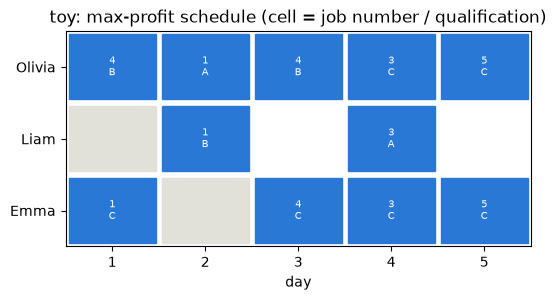

In [19]:
gantt(INST["toy"], best["toy"][1], "toy: max-profit schedule (cell = job number / qualification)")

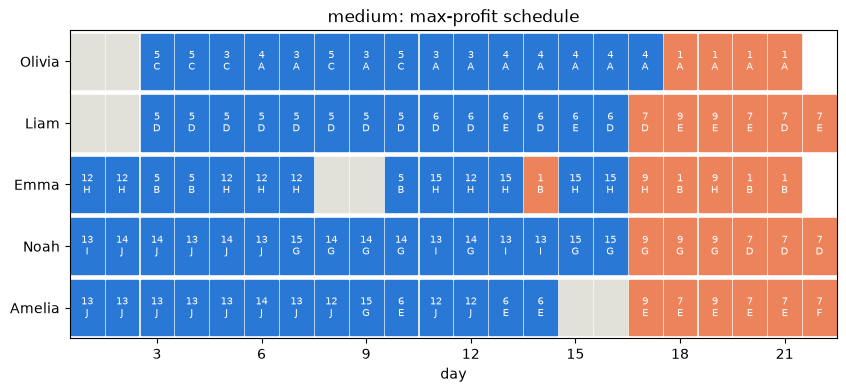

In [20]:
gantt(INST["medium"], best["medium"][1], "medium: max-profit schedule")

## 5. Pareto methods

* **ε-constraint** (textbook, two objectives): maximise profit subject to $f\le\varepsilon$, then
  set $\varepsilon=f-1$ and repeat until infeasible.
* **Disjunctive exclusion** (any number of objectives): after each point $p$, add the constraint
  "beat $p$ strictly on at least one objective". The search stops when the model is infeasible.

Both are **exact** when every solve is proven optimal and the search ends infeasible. That case is
reported as `exact = True`. If the time budget runs out, the result is a set of valid,
mutually non-dominated schedules, and `proven` marks the points that are guaranteed Pareto-optimal.

In [21]:
def key(p, objs):
    return tuple(SENSE[o] * p[o] for o in objs)


def dominates(a, b):
    return a != b and all(x <= y for x, y in zip(a, b, strict=True))


def nondominated(points, objs):
    pts = {key(p, objs): p for p in sorted(points, key=lambda p: p["proven"])}  # proven copy wins
    return [pts[k] for k in sorted(pts) if not any(dominates(o, k) for o in pts)]


def finish(front, objs, status):
    exact = status == "INFEASIBLE" and all(p["proven"] for p in front)
    return nondominated(front, objs), exact

In [22]:
def epsilon_2d(I, obj, tl=TL, budget=BUDGET):
    objs, t0, front, status = ["profit", obj], time.time(), [], "UNKNOWN"
    M = build(I, objs)
    while (left := budget - (time.time() - t0)) > 0:
        status, p = solve(M, I, objs, min(tl, left))
        if p is None:
            break
        front.append(p)
        if p[obj] == M.dom[obj][0]:  # nothing below the minimum: done
            status = "INFEASIBLE"
            break
        M.m.proto.variables[M.v[obj].index].domain[1] = p[obj] - 1  # epsilon = f - 1
    return finish(front, objs, status)

In [23]:
def pareto(I, objs, tl=TL, budget=BUDGET):
    M, t0, front, status = build(I, objs), time.time(), [], "UNKNOWN"
    while (left := budget - (time.time() - t0)) > 0:
        status, p = solve(M, I, objs, min(tl, left))
        if p is None:
            break
        front.append(p)
        lits = [M.m.new_bool_var("") for _ in objs]
        for o, lit in zip(objs, lits, strict=True):  # beat p strictly on some objective
            M.m.add(SENSE[o] * M.v[o] <= SENSE[o] * p[o] - 1).only_enforce_if(lit)
        M.m.add_bool_or(lits)
    return finish(front, objs, status)

In [24]:
def table(front, objs=OBJS):
    return pd.DataFrame(front)[[*objs, "proven"]]


def payoff(front, objs, min_profit):
    """Best point for each objective among the points at or above a reservation profit."""
    df = table(front, objs)
    df = df[df.profit >= min_profit]
    return pd.DataFrame({o: df.loc[(SENSE[o] * df[o]).idxmin(), objs] for o in objs}).T

In [25]:
def plot_2d(front, obj, ax, title=""):
    """Faint dots: every point. Staircase: the points that are non-dominated in this 2D view."""
    df, nd = table(front), table(nondominated(front, ["profit", obj])).sort_values(obj)
    ax.scatter(df[obj], df.profit, color=LIGHT, s=15, zorder=1)
    ax.step(nd[obj], nd.profit, where="post", color=GREY, zorder=2)
    ax.scatter(
        nd[obj], nd.profit, c=[BLUE if p else "white" for p in nd.proven], edgecolors=BLUE, zorder=3
    )
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, min_n_ticks=1))
    ax.set_xlim(df[obj].min() - 0.5, df[obj].max() + 0.5)
    ax.set(xlabel=obj, ylabel="profit", title=title)
    ax.grid(color=GREY, lw=0.5)


def parallel(front, objs=OBJS):
    df = table(front, objs)[objs]
    ax = ((df - df.min()) / (df.max() - df.min()).replace(0, 1)).T.plot(
        legend=False, color=BLUE, alpha=0.35, figsize=(9, 4)
    )
    ax.set(ylabel="value scaled to [0, 1] on the front", title="one line = one Pareto point")

## 6. Toy instance: exact fronts

### Check: both methods give the same front for every pair (profit, X)

In [26]:
toy = INST["toy"]
check = {o: (epsilon_2d(toy, o), pareto(toy, ["profit", o])) for o in OBJS[1:]}
pd.DataFrame(
    {
        o: {
            "points": len(e[0]),
            "both exact": e[1] and d[1],
            "same front": [key(p, ["profit", o]) for p in e[0]]
            == [key(p, ["profit", o]) for p in d[0]],
        }
        for o, (e, d) in check.items()
    }
)

,duration,projects_per_staff,late_jobs,team_size,imbalance
points,3,3,1,3,6
both exact,True,True,True,True,True
same front,True,True,True,True,True


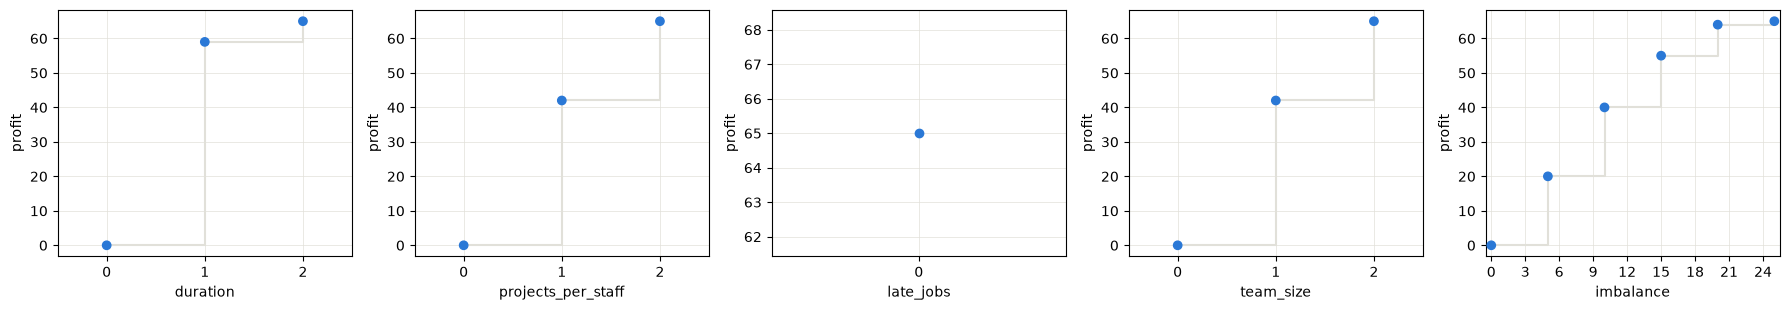

In [27]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, (o, ((front, _), _)) in zip(axes, check.items(), strict=True):
    plot_2d(front, o, ax)
fig.tight_layout()